## 0. Setup

In [1]:
import json, re, random, zipfile, shutil, urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageOps
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE  = torch.float16 if DEVICE == "cuda" else torch.float32
print("Device:", DEVICE)

Device: cuda


## 1. Dataset choice

| | **COCO 2017 val** (chosen) | Flickr30k |
|---|---|---|
| Images | 5,000 | 31,783 |
| Captions / image | ~5 | 5 |
| Download | ~1 GB, direct link | request form / HF mirror |
| T2I benchmark | standard (FID, CLIPScore) | less common |
| Content | 80 object categories, everyday scenes | mostly people & activities |

**Why COCO val2017:** it's already in our 1k–5k target range, downloads directly, and generation results are comparable with published numbers.
Set `N_TARGET` below to 1000 for fast iteration and 5000 for the final run.

In [12]:
# ---- Config ----
DATA_DIR  = Path("data")
RAW_DIR   = DATA_DIR / "raw" / "coco"
PROC_DIR  = DATA_DIR / "processed"
IMG_OUT   = PROC_DIR / "images"
for d in (RAW_DIR, IMG_OUT): d.mkdir(parents=True, exist_ok=True)

N_TARGET      = 5000     # final number of image–caption pairs (1000 for quick runs)
IMG_SIZE      = 512      # Stable Diffusion v1.x native resolution
MIN_SIDE      = 256      # drop images smaller than this on the short side
MAX_ASPECT    = 2.5      # drop extreme panoramas/strips (center-crop would lose too much)
MIN_WORDS, MAX_WORDS = 5, 40
CLIP_DROP_Q   = 0.10     # drop the weakest 10% of pairs by CLIP similarity
SPLIT         = (0.8, 0.1, 0.1)
CLIP_ID       = "openai/clip-vit-large-patch14"   # same text encoder as SD v1.5

## 2. Download COCO 2017 val + captions
Skips anything already downloaded.

In [13]:
URLS = {
    "val2017.zip": "http://images.cocodataset.org/zips/val2017.zip",
    "annotations_trainval2017.zip": "http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
}

def download(url, dest):
    if dest.exists():
        print("exists:", dest.name); return
    print("downloading:", dest.name)
    with tqdm(unit="B", unit_scale=True) as bar:
        def hook(b, bs, total):
            bar.total = total; bar.update(b * bs - bar.n)
        urllib.request.urlretrieve(url, dest, hook)

for name, url in URLS.items():
    download(url, RAW_DIR / name)

if not (RAW_DIR / "val2017").exists():
    zipfile.ZipFile(RAW_DIR / "val2017.zip").extractall(RAW_DIR)
cap_file = RAW_DIR / "annotations" / "captions_val2017.json"
if not cap_file.exists():
    with zipfile.ZipFile(RAW_DIR / "annotations_trainval2017.zip") as z:
        z.extract("annotations/captions_val2017.json", RAW_DIR)

IMG_DIR = RAW_DIR / "val2017"
print("images on disk:", len(list(IMG_DIR.glob("*.jpg"))))

exists: val2017.zip
exists: annotations_trainval2017.zip
images on disk: 5000


## 3. Load into a DataFrame & first look

In [14]:
ann = json.load(open(cap_file))
images = pd.DataFrame(ann["images"])[["id", "file_name", "width", "height"]].rename(columns={"id": "image_id"})
caps   = pd.DataFrame(ann["annotations"])[["image_id", "caption"]]
raw = caps.merge(images, on="image_id")

print(f"{len(images):,} images | {len(caps):,} captions | {len(caps)/len(images):.2f} captions/image")
raw.head()

5,000 images | 25,014 captions | 5.00 captions/image


,image_id,caption,file_name,width,height
0,179765,A black Honda motorcycle parked in front of a ...,000000179765.jpg,640,480
1,179765,A Honda motorcycle parked in a grass driveway,000000179765.jpg,640,480
2,190236,An office cubicle with four different types of...,000000190236.jpg,640,393
3,331352,A small closed toilet in a cramped space.,000000331352.jpg,351,500
4,517069,Two women waiting at a bench next to a street.,000000517069.jpg,640,480


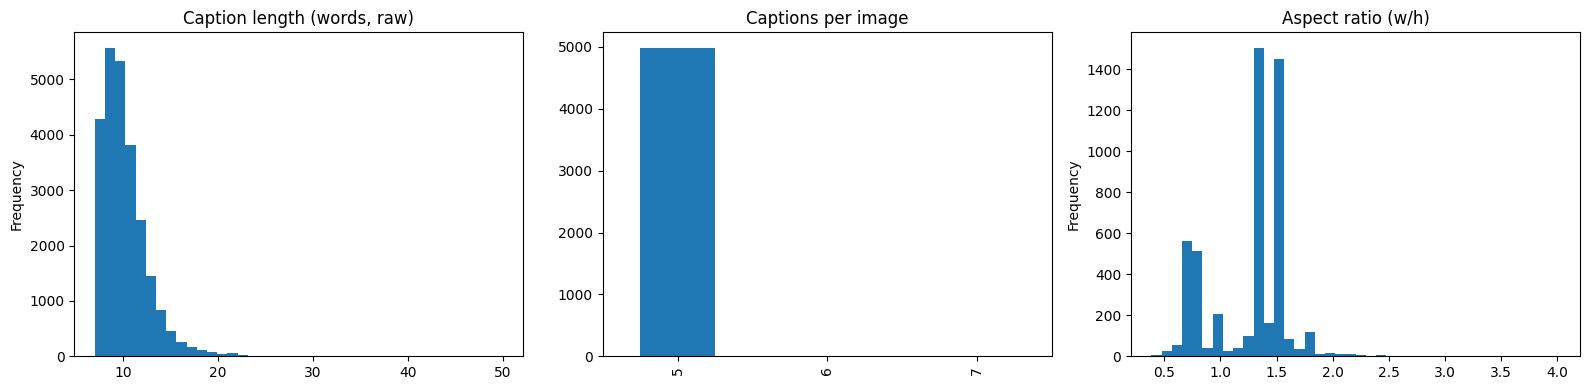

In [15]:
raw["n_words_raw"] = raw.caption.str.split().str.len()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
raw.n_words_raw.plot.hist(bins=40, ax=ax[0], title="Caption length (words, raw)")
raw.groupby("image_id").size().value_counts().sort_index().plot.bar(ax=ax[1], title="Captions per image")
images.assign(ar=images.width / images.height).ar.plot.hist(bins=40, ax=ax[2], title="Aspect ratio (w/h)")
plt.tight_layout(); plt.show()

## 4. Caption cleaning
Rules:
1. Normalize whitespace, strip, lowercase, remove stray quotes/odd characters, collapse repeated punctuation
2. Standardize ending to a single period
3. Drop empty / too short (< 5 words) / too long (> 40 words; also keeps us under CLIP's 77-token limit)
4. Drop exact duplicate captions **within** the same image
5. Verify token length with the real CLIP tokenizer (anything that would be truncated is dropped)

In [16]:
import unicodedata
def clean_caption(c: str) -> str:
    c = unicodedata.normalize("NFKD", c).encode("ascii", "ignore").decode()  # café -> cafe
    c = c.strip().lower()
    c = c.replace("\n", " ").replace("\t", " ")
    c = re.sub(r"[\"`]", "", c)                     # quotes
    c = re.sub(r"[^a-z0-9\s,.'\-!?&/]", " ", c)    # odd chars
    c = re.sub(r"([.,!?])\1+", r"\1", c)           # repeated punctuation
    c = re.sub(r"\s+([.,!?])", r"\1", c)           # space before punctuation
    c = re.sub(r"\s+", " ", c).strip()
    c = c.rstrip(" .,!?")
    return (c + ".") if c else ""

df = raw.copy()
df["caption_raw"] = df.caption
df["caption"] = df.caption.map(clean_caption)
df["n_words"] = df.caption.str.split().str.len()

log = {"raw captions": len(df)}
df = df[df.caption.str.len() > 0];                          log["after empty"] = len(df)
df = df[df.n_words.between(MIN_WORDS, MAX_WORDS)];          log["after length filter"] = len(df)
df = df.drop_duplicates(["image_id", "caption"]);           log["after dedupe"] = len(df)

# examples of what changed
changed = df[df.caption_raw.str.strip().str.lower().str.rstrip(" .") + "." != df.caption]
display(changed[["caption_raw", "caption"]].head(8))
log

,caption_raw,caption
152,A close up of a bicycle parked on a train pla...,a close up of a bicycle parked on a train plat...
155,The bicycle is locked to the metal pole as the...,the bicycle is locked to the metal pole as the...
208,a light green kitchen some cabinets a dish wa...,a light green kitchen some cabinets a dish was...
349,A piece of dutch chocolate cake with a fork o...,a piece of dutch chocolate cake with a fork on...
510,The reflection of a man taking a picture in a...,the reflection of a man taking a picture in a ...
538,a room with a television set a stool and some...,a room with a television set a stool and some ...
633,The white and yellow clock with a red roof rea...,the white and yellow clock with a red roof rea...
695,A blue motorcycle parked on display next to o...,a blue motorcycle parked on display next to ot...


{'raw captions': 25014,
 'after empty': 25014,
 'after length filter': 25012,
 'after dedupe': 24998}

In [17]:
from transformers import CLIPTokenizer
tok = CLIPTokenizer.from_pretrained(CLIP_ID)
df["n_tokens"] = [len(x) for x in tok(df.caption.tolist(), truncation=False)["input_ids"]]
df = df[df.n_tokens <= 77];  log["after token check"] = len(df)
print("max tokens:", df.n_tokens.max(), "| mean:", round(df.n_tokens.mean(), 1))

max tokens: 52 | mean: 13.8


## 5. Image validation
Drop images that are corrupt, too small, or extremely elongated. Grayscale/CMYK/RGBA images are kept but converted to RGB in step 6.

In [18]:
def check_image(path):
    try:
        with Image.open(path) as im:
            im.verify()                       # catches truncated/corrupt files
        with Image.open(path) as im:
            w, h = im.size
            return {"ok": True, "mode": im.mode, "w": w, "h": h}
    except Exception as e:
        return {"ok": False, "mode": None, "w": 0, "h": 0, "err": str(e)}

img_meta = []
for iid, fname in tqdm(df[["image_id", "file_name"]].drop_duplicates().values, desc="validating"):
    r = check_image(IMG_DIR / fname); r.update(image_id=iid); img_meta.append(r)
img_meta = pd.DataFrame(img_meta)
img_meta["short"]  = img_meta[["w", "h"]].min(axis=1)
img_meta["aspect"] = img_meta[["w", "h"]].max(axis=1) / img_meta.short.clip(lower=1)

print("modes:", img_meta["mode"].value_counts().to_dict())
bad = img_meta[~img_meta.ok | (img_meta.short < MIN_SIDE) | (img_meta.aspect > MAX_ASPECT)]
print(f"dropping {len(bad)} images: corrupt={(~img_meta.ok).sum()}, "
      f"small={(img_meta.short < MIN_SIDE).sum()}, extreme aspect={(img_meta.aspect > MAX_ASPECT).sum()}")

df = df[~df.image_id.isin(bad.image_id)]; log["after image validation"] = len(df)
print(f"{df.image_id.nunique():,} images remain")

validating:   0%|          | 0/5000 [00:00<?, ?it/s]

modes: {'RGB': 4990, 'L': 10}
dropping 42 images: corrupt=0, small=42, extreme aspect=16
4,958 images remain


## 6. Image preprocessing → 512×512 RGB
Resize the short side to 512 (Lanczos), center-crop to 512×512, fix EXIF rotation, convert to RGB, save as JPEG (q=95).
Center-crop matches how Stable Diffusion was trained; the aspect-ratio filter above limits how much gets cut off.

In [19]:
def preprocess(src, dst, size=IMG_SIZE):
    with Image.open(src) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        w, h = im.size
        s = size / min(w, h)
        im = im.resize((round(w * s), round(h * s)), Image.LANCZOS)
        w, h = im.size
        l, t = (w - size) // 2, (h - size) // 2
        im.crop((l, t, l + size, t + size)).save(dst, "JPEG", quality=95)

for fname in tqdm(df.file_name.unique(), desc="preprocessing"):
    dst = IMG_OUT / fname
    if not dst.exists():
        preprocess(IMG_DIR / fname, dst)
print("processed images:", len(list(IMG_OUT.glob('*.jpg'))))

preprocessing:   0%|          | 0/4958 [00:00<?, ?it/s]

processed images: 4958


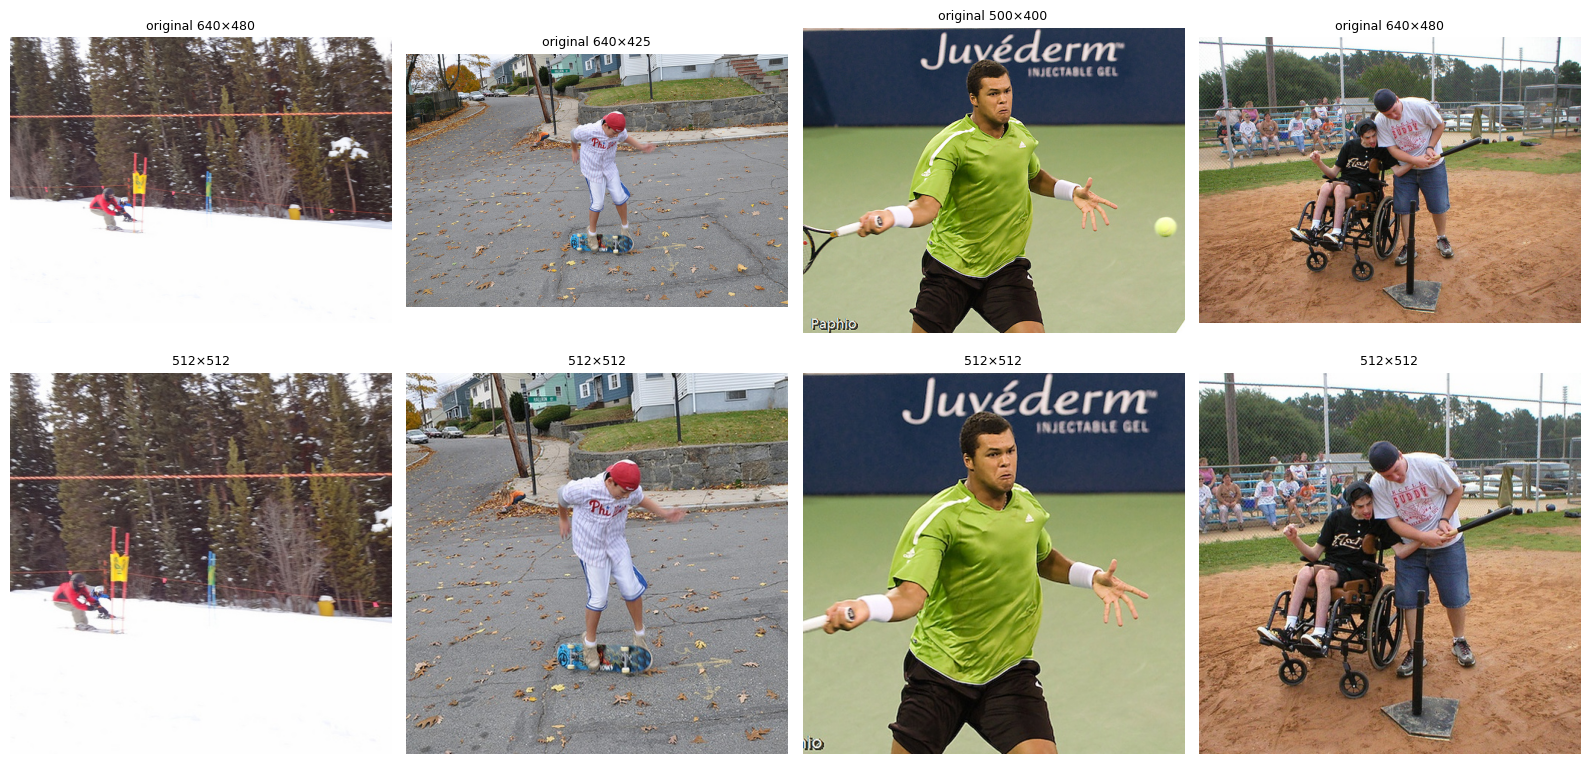

In [20]:
# before / after check
sample = df.drop_duplicates("image_id").sample(4, random_state=SEED)
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for i, (_, r) in enumerate(sample.iterrows()):
    ax[0, i].imshow(Image.open(IMG_DIR / r.file_name)); ax[0, i].set_title(f"original {r.width}×{r.height}", fontsize=9)
    ax[1, i].imshow(Image.open(IMG_OUT / r.file_name)); ax[1, i].set_title("512×512", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 7. CLIP image–text alignment filter
Score every caption against its (processed) image with CLIP ViT-L/14. Then:
- keep the **best-matching caption** per image as the primary training/eval caption
- drop the weakest `CLIP_DROP_Q` of pairs (mismatched or vague captions)

All captions + scores are still saved, in case the team wants multi-caption training later.

In [22]:
from transformers import CLIPModel, CLIPProcessor
clip = CLIPModel.from_pretrained(CLIP_ID, torch_dtype=DTYPE).to(DEVICE).eval()
proc = CLIPProcessor.from_pretrained(CLIP_ID)

@torch.no_grad()
def embed_images(paths, bs=32):
    out = []
    for i in tqdm(range(0, len(paths), bs), desc="image emb"):
        ims = [Image.open(p).convert("RGB") for p in paths[i:i+bs]]
        px = proc(images=ims, return_tensors="pt")["pixel_values"].to(DEVICE, DTYPE)
        e = clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output)
        out.append((e / e.norm(dim=-1, keepdim=True)).float().cpu())
    return torch.cat(out)

@torch.no_grad()
def embed_texts(texts, bs=128):
    out = []
    for i in tqdm(range(0, len(texts), bs), desc="text emb"):
        t = proc(text=texts[i:i+bs], padding=True, truncation=True, max_length=77, return_tensors="pt").to(DEVICE)
        e = clip.text_projection(clip.text_model(input_ids=t["input_ids"], attention_mask=t["attention_mask"]).pooler_output)
        out.append((e / e.norm(dim=-1, keepdim=True)).float().cpu())
    return torch.cat(out)

uniq = df.drop_duplicates("image_id")[["image_id", "file_name"]].reset_index(drop=True)
img_emb = embed_images([IMG_OUT / f for f in uniq.file_name])
row_of = {iid: i for i, iid in enumerate(uniq.image_id)}

df = df.reset_index(drop=True)
txt_emb = embed_texts(df.caption.tolist())
idx = torch.tensor(df.image_id.map(row_of).values)
df["clip_sim"] = (txt_emb * img_emb[idx]).sum(-1).numpy()
df.clip_sim.describe()

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

image emb:   0%|          | 0/155 [00:00<?, ?it/s]

text emb:   0%|          | 0/194 [00:00<?, ?it/s]

,clip_sim
count,24788.000000
mean,0.256018
std,0.038731
min,0.077903
25%,0.230762
50%,0.256539
75%,0.281340
max,0.477074


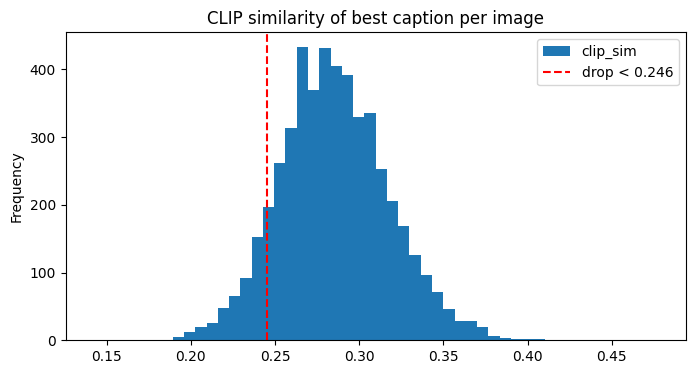

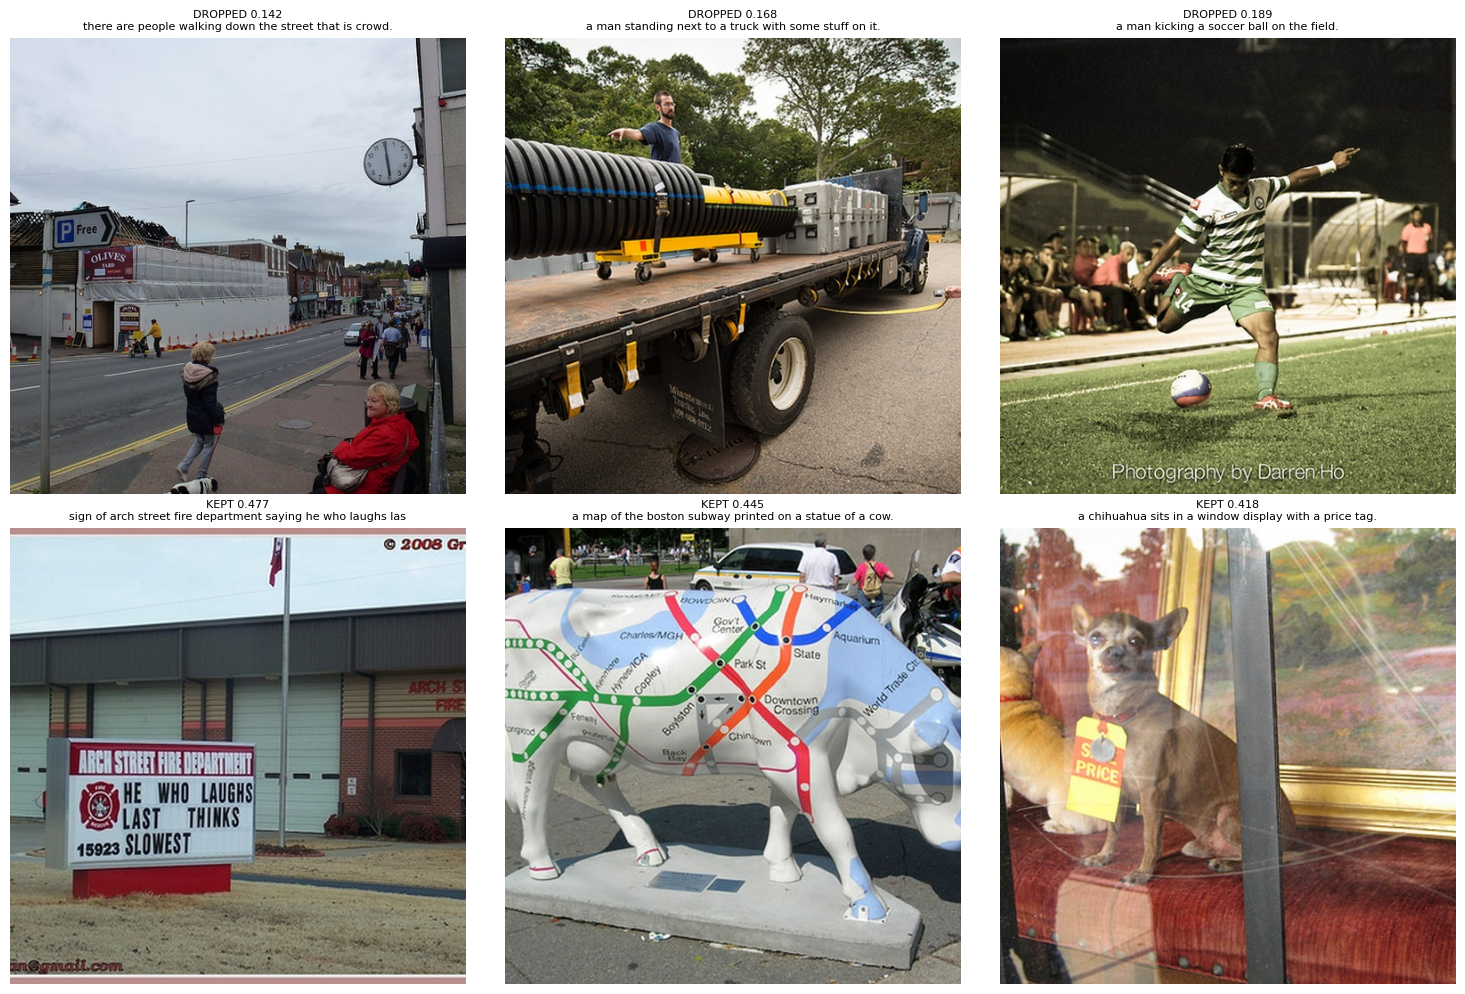

In [23]:
best = df.loc[df.groupby("image_id").clip_sim.idxmax()].copy()
thresh = best.clip_sim.quantile(CLIP_DROP_Q)
fig, ax = plt.subplots(figsize=(8, 4))
best.clip_sim.plot.hist(bins=50, ax=ax, title="CLIP similarity of best caption per image")
ax.axvline(thresh, color="red", ls="--", label=f"drop < {thresh:.3f}"); ax.legend(); plt.show()

# what the filter removes vs keeps
worst, top = best.nsmallest(3, "clip_sim"), best.nlargest(3, "clip_sim")
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for row, sub, lab in [(0, worst, "DROPPED"), (1, top, "KEPT")]:
    for j, (_, r) in enumerate(sub.iterrows()):
        ax[row, j].imshow(Image.open(IMG_OUT / r.file_name)); ax[row, j].axis("off")
        ax[row, j].set_title(f"{lab} {r.clip_sim:.3f}\n{r.caption[:60]}", fontsize=8)
plt.tight_layout(); plt.show()

best = best[best.clip_sim >= thresh];  log["images after CLIP filter"] = len(best)

## 8. Sample to target size & split
Split is by **image**, so no image leaks across train/val/test.

In [24]:
best = best.sample(min(N_TARGET, len(best)), random_state=SEED).reset_index(drop=True)
n = len(best); n_tr, n_va = int(SPLIT[0] * n), int(SPLIT[1] * n)
best["split"] = ["train"] * n_tr + ["val"] * n_va + ["test"] * (n - n_tr - n_va)
best["image_path"] = best.file_name.map(lambda f: str(IMG_OUT / f))
best.split.value_counts()

,count
split,
train,3569
test,447
val,446


## 9. Export

In [25]:
cols = ["image_id", "file_name", "image_path", "caption", "n_words", "n_tokens", "clip_sim", "split"]
best[cols].to_csv(PROC_DIR / "pairs_clean.csv", index=False)

keep_ids = set(best.image_id)
all_caps = df[df.image_id.isin(keep_ids)].merge(best[["image_id", "split"]], on="image_id")
all_caps[["image_id", "file_name", "caption", "caption_raw", "n_tokens", "clip_sim", "split"]] \
    .to_csv(PROC_DIR / "captions_all.csv", index=False)

# remove processed images that didn't make the final cut
for p in IMG_OUT.glob("*.jpg"):
    if p.name not in set(best.file_name): p.unlink()

print("pairs_clean.csv :", len(best), "rows")
print("captions_all.csv:", len(all_caps), "rows")
print("images folder   :", len(list(IMG_OUT.glob('*.jpg'))))

pairs_clean.csv : 4462 rows
captions_all.csv: 22307 rows
images folder   : 4462


## 10. Dataset summary (for the proposal)

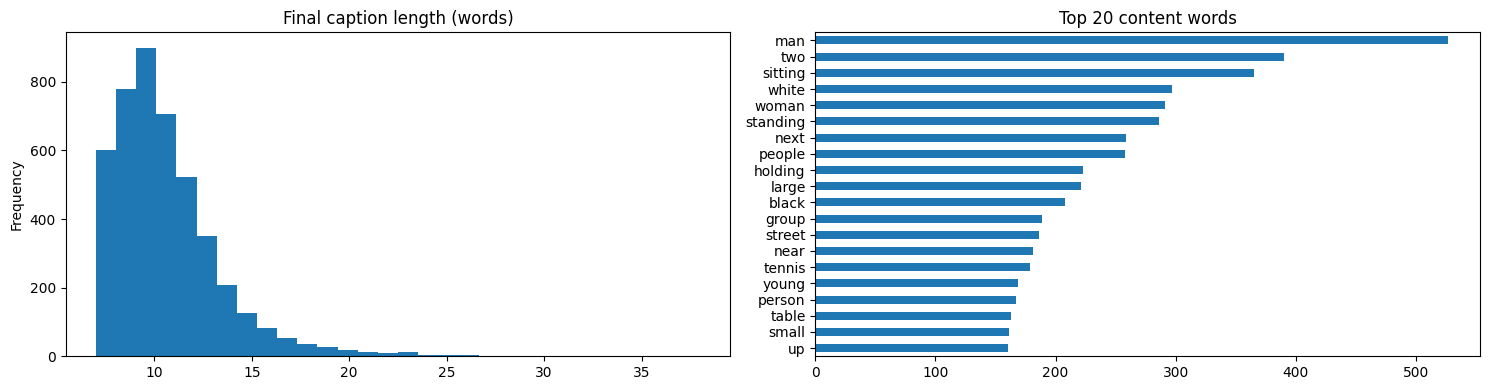

,count
raw captions,25014
after empty,25014
after length filter,25012
after dedupe,24998
after token check,24998
after image validation,24788
images after CLIP filter,4462


# Dataset card — COCO 2017 val (curated)
- Source: MS-COCO 2017 validation split (5,000 images, 25,014 captions)
- Final: **4,462 image–caption pairs** at 512×512 RGB
- Split: {'train': np.int64(3569), 'test': np.int64(447), 'val': np.int64(446)}
- Caption length: mean 11.0 words / 14.5 CLIP tokens (max 77)
- Mean CLIP ViT-L/14 image–text similarity: 0.291 (filter threshold 0.246)

## Cleaning funnel
- raw captions: 25,014
- after empty: 25,014
- after length filter: 25,012
- after dedupe: 24,998
- after token check: 24,998
- after image validation: 24,788
- images after CLIP filter: 4,462

## Steps
1. Caption normalization (case, whitespace, punctuation, odd chars), length filter 5–40 words, per-image dedupe, CLIP token check
2. Image validation (corrupt, short side < 256px, aspect > 2.5)
3. EXIF fix, RGB, Lanczos resize + center-crop to 512
4. CLIP alignment: best caption per image, bottom 10% dropped
5. Image-level (0.8, 0.1, 0.1) train/val/test split, seed 42



In [26]:
stop = set("a an the of on in with and is are to at for by its it his her their there this that".split())
words = Counter(w.strip(".,!?") for c in best.caption for w in c.split() if w.strip(".,!?") not in stop)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
best.n_words.plot.hist(bins=30, ax=ax[0], title="Final caption length (words)")
pd.Series(dict(words.most_common(20))).plot.barh(ax=ax[1], title="Top 20 content words"); ax[1].invert_yaxis()
plt.tight_layout(); plt.savefig(PROC_DIR / "dataset_summary.png", dpi=150); plt.show()

funnel = pd.Series(log, name="count")
display(funnel.to_frame())
funnel_md = "\n".join(f"- {k}: {v:,}" for k, v in log.items())

card = f"""# Dataset card — COCO 2017 val (curated)
- Source: MS-COCO 2017 validation split (5,000 images, {len(caps):,} captions)
- Final: **{len(best):,} image–caption pairs** at {IMG_SIZE}×{IMG_SIZE} RGB
- Split: {dict(best.split.value_counts())}
- Caption length: mean {best.n_words.mean():.1f} words / {best.n_tokens.mean():.1f} CLIP tokens (max 77)
- Mean CLIP ViT-L/14 image–text similarity: {best.clip_sim.mean():.3f} (filter threshold {thresh:.3f})

## Cleaning funnel
{funnel_md}

## Steps
1. Caption normalization (case, whitespace, punctuation, odd chars), length filter {MIN_WORDS}–{MAX_WORDS} words, per-image dedupe, CLIP token check
2. Image validation (corrupt, short side < {MIN_SIDE}px, aspect > {MAX_ASPECT})
3. EXIF fix, RGB, Lanczos resize + center-crop to {IMG_SIZE}
4. CLIP alignment: best caption per image, bottom {int(CLIP_DROP_Q*100)}% dropped
5. Image-level {SPLIT} train/val/test split, seed {SEED}
"""
(PROC_DIR / "dataset_card.md").write_text(card)
print(card)

##Embedding / generation notebooks
```python
import pandas as pd
pairs = pd.read_csv("data/processed/pairs_clean.csv")
train = pairs[pairs.split == "train"]   # image_path, caption
```
Add `data/` to `.gitignore`; commit only this notebook, `dataset_card.md` and `dataset_summary.png`.